# Palmer Penguines : Exploratory Data Analysis And Species Classification

## Project Overview

This project explores the Palmer Penguins dataset to
understand the physical characteristics of different penguin
species and identify patterns through exploratory data analysis.

The project also implements machine learning classification
models to predict penguin species based on their physical
measurements.

## Project Objectives

- Understand the structure and characteristics of the dataset.
- Identify and handle missing values.
- Perform exploratory data analysis.
- Analyze relationships between numerical and categorical features.
- Identify the distinguishing characteristics of penguin species.
- Build and compare machine learning classification models.
- Evaluate model performance using appropriate metrics.

## Tools and Technologies

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

## 1. Problem Statement

Penguin species exhibit differences in their physical
characteristics, including bill length, bill depth,
flipper length and body mass.

The objective of this project is to analyze these
characteristics and develop a machine learning model
that accurately classifies penguins into three species:

- Adelie
- Chinstrap
- Gentoo

This is a supervised machine learning problem involving
multiclass classification.

## 2. Importing Libraries

The following libraries are used for data manipulation,
statistical analysis, visualization, preprocessing,
model training and performance evaluation.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File management
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)

# Visualization theme
sns.set_theme(style="whitegrid", palette="Set2")

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120

# Project directories
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
VISUAL_DIR = ROOT / "visuals"

DATA_DIR.mkdir(exist_ok=True)
VISUAL_DIR.mkdir(exist_ok=True)

## 3. Data Collection

The Palmer Penguins dataset contains measurements of
344 penguins belonging to three different species.

The observations were collected between 2007 and 2009
in the Palmer Archipelago, Antarctica.

The dataset used in this project is obtained through
the Seaborn library.

### Dataset Source

- Palmer Penguins: https://allisonhorst.github.io/palmerpenguins/
- Dataset authors: Allison Horst, Alison Hill and Kristen Gorman
- DOI: https://doi.org/10.5281/zenodo.3960218
- Data License: CC0

In [2]:
# Load the dataset
data_path = DATA_DIR / "penguins.csv"

if data_path.exists():
    df = pd.read_csv(data_path)
else:
    df = sns.load_dataset("penguins")
    df.to_csv(data_path, index=False)

df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## 4. Data Understanding

Data understanding involves examining the structure,
dimensions, data types and characteristics of the dataset
before performing data cleaning and analysis.

### 4.1 Data Dictionary

| Feature | Description | Data Type |
|---|---|---|
| species | Penguin species | Categorical |
| island | Island of observation | Categorical |
| bill_length_mm | Bill length in millimeters | Numerical |
| bill_depth_mm | Bill depth in millimeters | Numerical |
| flipper_length_mm | Flipper length in millimeters | Numerical |
| body_mass_g | Body mass in grams | Numerical |
| sex | Biological sex | Categorical |

### Target Variable

The target variable is `species`.

### Predictor Variables

The primary predictor variables are the four physical
measurements of the penguins.

### 4.2 Dataset Dimensions

Determine the total number of observations and features
available in the dataset.

In [3]:
print("Total observations:", df.shape[0])
print("Total columns:", df.shape[1])

Total observations: 344
Total columns: 7


### 4.3 Dataset Structure and Data Types

Inspect the column names, data types and non-null values
to identify potential data quality issues.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [5]:
df.dtypes.to_frame(name="Data Type")

,Data Type
species,str
island,str
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,str


### 4.4 Previewing the Dataset

Examine sample observations to understand how the data
is organized.

In [6]:
df.sample(5, random_state=42)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
194,Chinstrap,Dream,50.9,19.1,196.0,3550.0,Male
157,Chinstrap,Dream,45.2,17.8,198.0,3950.0,Female
225,Gentoo,Biscoe,46.5,13.5,210.0,4550.0,Female
208,Chinstrap,Dream,45.2,16.6,191.0,3250.0,Female
318,Gentoo,Biscoe,48.4,14.4,203.0,4625.0,Female


## 5. Data Quality Assessment

Before performing exploratory data analysis, the dataset
is examined for missing values, duplicate records and
inconsistent categorical values.

### 5.1 Missing Value Analysis

In [7]:
missing_data = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_data.sort_values(
    by="Missing Values",
    ascending=False
)

,Missing Values,Missing Percentage
sex,11,3.20
bill_depth_mm,2,0.58
bill_length_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
island,0,0.00
species,0,0.00


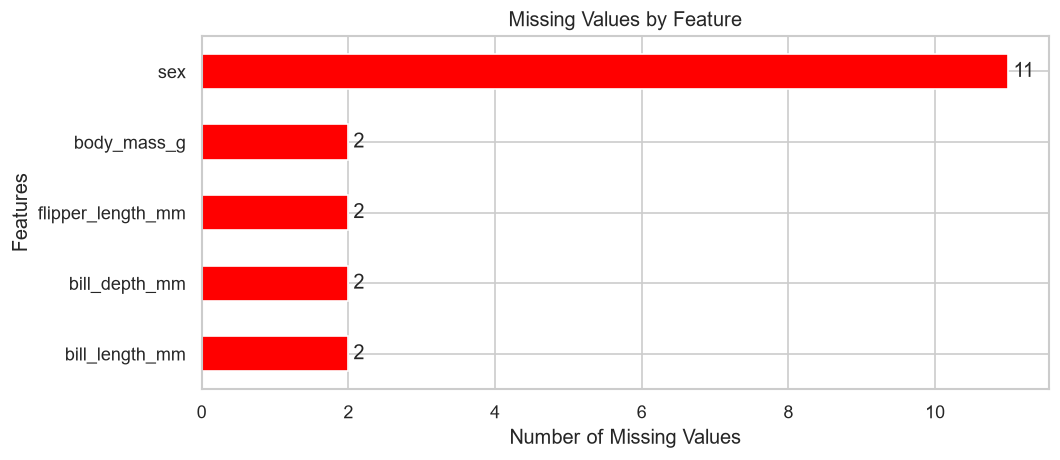

In [8]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values()

plt.figure(figsize=(9, 4))

ax = missing.plot(
    kind="barh",
    color="red"
)

ax.bar_label(ax.containers[0], padding=3)

plt.title("Missing Values by Feature")
plt.xlabel("Number of Missing Values")
plt.ylabel("Features")
plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "missing_values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Observations

- The sex column contains the highest number of missing values.
- Each numerical measurement column contains two missing values.
- The target variable does not contain missing values.
- Missing values should be handled before model training.

### 5.2 Duplicate Record Analysis

Identify duplicate observations that may affect the
reliability of the analysis.

In [9]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


### 5.3 Categorical Data Validation

Inspect unique values and their frequencies to identify
inconsistent categories or unexpected labels.

In [10]:
categorical_cols = ["species", "island", "sex"]

for col in categorical_cols:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))


Column: species
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Column: island
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

Column: sex
sex
Male      168
Female    165
NaN        11
Name: count, dtype: int64


#### Observations

- The dataset contains three penguin species.
- Adelie is the most frequently observed species.
- Chinstrap is the least frequently observed species.
- The class distribution is moderately imbalanced.
- Stratified sampling will be considered during the
  train-test split to preserve class proportions.

## 6. Data Cleaning and Preprocessing

Data cleaning is an essential step in the data science
workflow. It improves data quality and ensures reliable
analytical and machine learning results.

The following operations are performed:

- Handling missing values
- Removing duplicate records
- Validating data quality
- Preserving the original dataset

### 6.1 Creating a Working Copy

A separate copy of the original dataset is created to
preserve the raw data for future reference.

In [11]:
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (344, 7)
Working dataset shape: (344, 7)


### 6.2 Handling Missing Values

The dataset contains a small proportion of incomplete
observations.

Since only a small percentage of records contain missing
values, complete-case analysis is performed by removing
incomplete records.

This approach avoids introducing artificial measurements
through imputation. However, it may introduce bias if
the missing observations are not randomly distributed.

In [12]:
rows_before = len(df_clean)

df_clean = df_clean.dropna().reset_index(drop=True)

rows_after = len(df_clean)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", rows_after)
print("Rows removed:", rows_before - rows_after)

print("Data retained:",
      round(rows_after / rows_before * 100, 2), "%")

Rows before cleaning: 344
Rows after cleaning: 333
Rows removed: 11
Data retained: 96.8 %


#### Observations

- The original dataset contains 344 observations.
- After removing incomplete records, 333 observations remain.
- Approximately 96.80% of the original data is retained.
- The amount of data removed is relatively small.

### 6.3 Duplicate Record Treatment

Duplicate records are identified and removed to prevent
repeated observations from influencing the analysis.

In [13]:
duplicates = df_clean.duplicated().sum()

print("Duplicate records:", duplicates)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Dataset shape:", df_clean.shape)

Duplicate records: 0
Dataset shape: (333, 7)


### 6.4 Data Quality Validation

After performing data cleaning, the dataset is validated
to ensure that missing values and duplicate records have
been addressed successfully.

In [14]:
quality_report = pd.DataFrame({
    "Original Dataset": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ],
    "Cleaned Dataset": [
        df_clean.shape[0],
        df_clean.shape[1],
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum()
    ]
}, index=[
    "Total Records",
    "Total Features",
    "Missing Values",
    "Duplicate Records"
])

quality_report

,Original Dataset,Cleaned Dataset
Total Records,344,333
Total Features,7,7
Missing Values,19,0
Duplicate Records,0,0


In [15]:
df_clean.to_csv(
    DATA_DIR / "penguins_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


#### Data Cleaning Summary

The cleaned dataset contains 333 observations and seven
columns, with no missing values or duplicate records.

The cleaned dataset is saved separately to ensure
reproducibility while preserving the original raw dataset.

## 7. Descriptive Statistical Analysis

Descriptive statistics summarize the central tendency,
dispersion and distribution of numerical features.

The analysis includes:

- Mean
- Median
- Standard deviation
- Minimum and maximum values
- Quartiles

In [16]:
numeric_cols = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

df_clean[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
bill_length_mm,333.0,43.99,5.47,32.1,39.5,44.5,48.6,59.6
bill_depth_mm,333.0,17.16,1.97,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,333.0,200.97,14.02,172.0,190.0,197.0,213.0,231.0
body_mass_g,333.0,4207.06,805.22,2700.0,3550.0,4050.0,4775.0,6300.0


In [17]:
summary_stats = df_clean[numeric_cols].agg([
    "mean",
    "median",
    "std",
    "min",
    "max",
    "skew"
]).T.round(2)

summary_stats

,mean,median,std,min,max,skew
bill_length_mm,43.99,44.5,5.47,32.1,59.6,0.05
bill_depth_mm,17.16,17.3,1.97,13.1,21.5,-0.15
flipper_length_mm,200.97,197.0,14.02,172.0,231.0,0.36
body_mass_g,4207.06,4050.0,805.22,2700.0,6300.0,0.47


#### Observations

- The average bill length is approximately 44 mm.
- The average flipper length is approximately 201 mm.
- Body mass ranges from 2700 g to 6300 g.
- The variation in physical measurements suggests that
  these features may help distinguish penguin species.
- Further species-level analysis is required to confirm
  these relationships.

## 8. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to discover
patterns, understand distributions, identify relationships
and generate meaningful insights from the dataset.

### 8.1 Univariate Analysis

Univariate analysis examines one variable at a time.

The analysis focuses on:

- Species distribution
- Island distribution
- Sex distribution
- Numerical feature distributions
- Potential outliers

### 8.1.1 Distribution of Penguin Species

Research Question:

Which penguin species is most frequently represented
in the cleaned dataset?

In [18]:
species_counts = df_clean["species"].value_counts()

species_counts

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

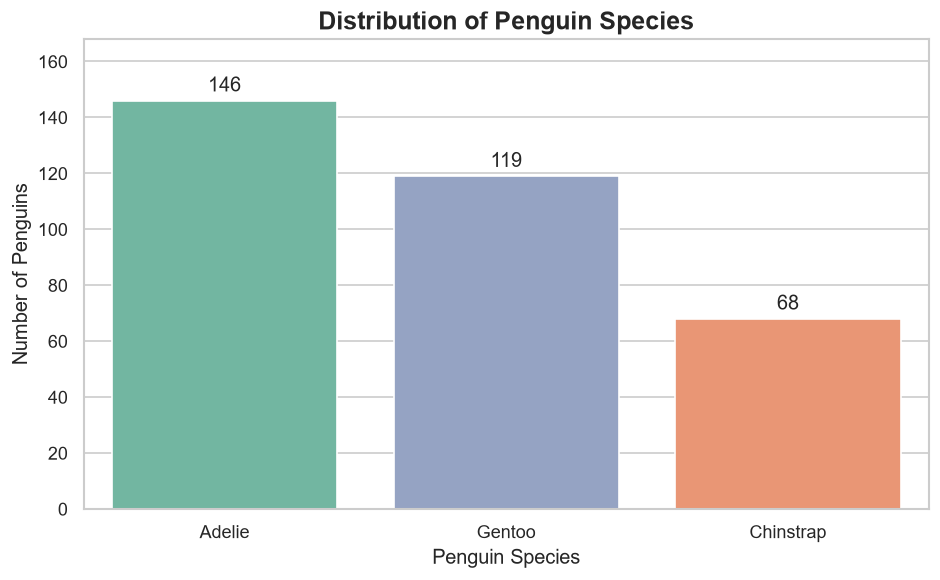

In [19]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_clean,
    x="species",
    hue="species",
    order=species_counts.index,
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title(
    "Distribution of Penguin Species",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Penguin Species")
plt.ylabel("Number of Penguins")
plt.ylim(0, species_counts.max() * 1.15)

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "species_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Key Insights

- Adelie is the most frequently represented species,
  with 146 observations.
- Gentoo is the second most represented species,
  with 119 observations.
- Chinstrap has the lowest representation,
  with 68 observations.
- The dataset exhibits moderate class imbalance.
- Stratified sampling and macro-averaged evaluation
  metrics will be considered during model development.

### 8.1.2 Distribution of Penguins Across Islands

Research Question:

Which island has the highest number of penguin
observations in the dataset?

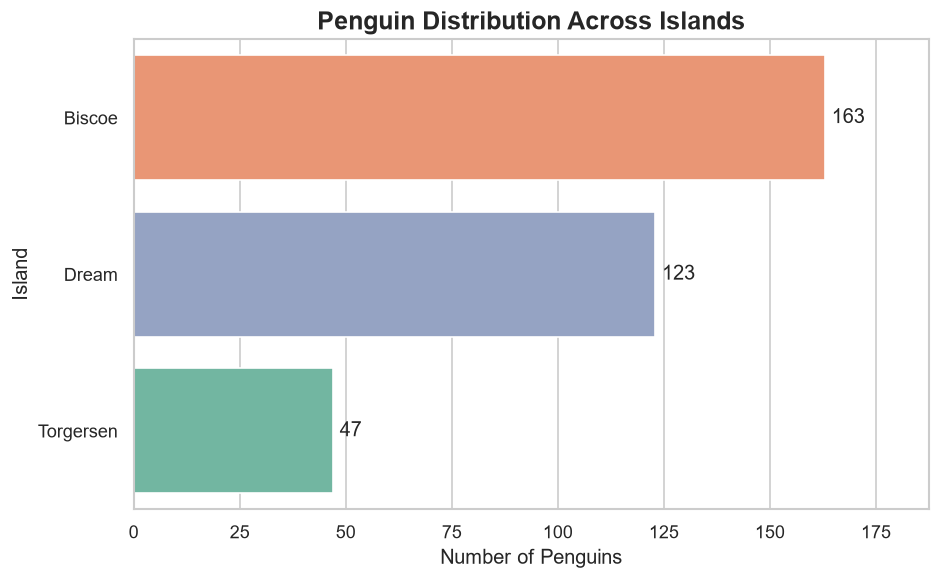

In [20]:
island_counts = df_clean["island"].value_counts()

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_clean,
    y="island",
    hue="island",
    order=island_counts.index,
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=4)

plt.title(
    "Penguin Distribution Across Islands",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Penguins")
plt.ylabel("Island")
plt.xlim(0, island_counts.max() * 1.15)

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "island_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Key Insights

- Biscoe Island has the highest number of observations.
- Dream Island has the second-highest representation.
- Torgersen Island has the lowest number of observations.
- The distribution reflects the collected samples and
  does not necessarily represent the actual population
  size of penguins on each island.

### 8.1.3 Distribution by Sex

Research Question:

Is the distribution of male and female penguins
balanced within the cleaned dataset?

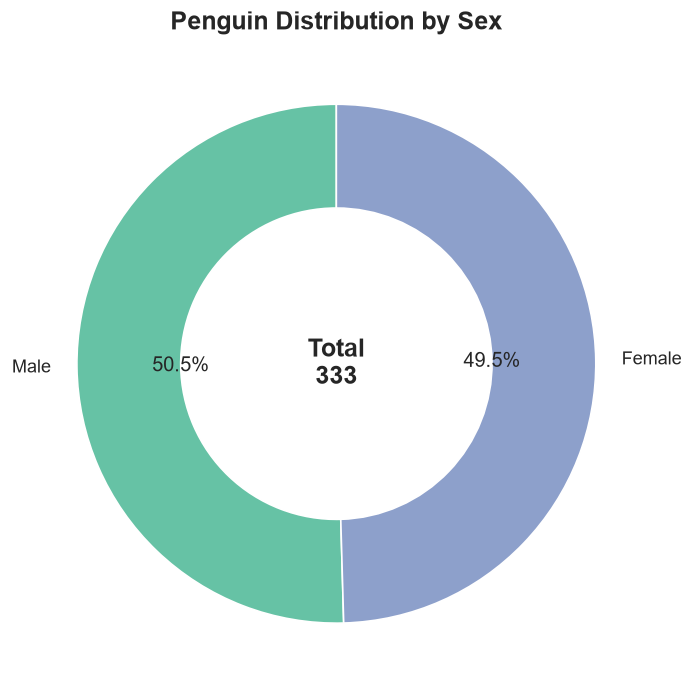

In [21]:
sex_counts = df_clean["sex"].value_counts()

plt.figure(figsize=(7, 6))

plt.pie(
    sex_counts.values,
    labels=sex_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#66C2A5", "#8DA0CB"],
    wedgeprops={
        "width": 0.4,
        "edgecolor": "white"
    }
)

plt.text(
    0, 0,
    f"Total\n{len(df_clean)}",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

plt.title(
    "Penguin Distribution by Sex",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "sex_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Key Insights

- The cleaned dataset contains 168 male and 165 female
  penguins.
- Both categories are almost equally represented.
- The dataset has a balanced distribution with respect
  to sex.

### 8.1.4 Distribution of Numerical Features

Histograms and Kernel Density Estimation (KDE) curves
are used to examine the distribution, spread, skewness
and potential multiple peaks of numerical variables.

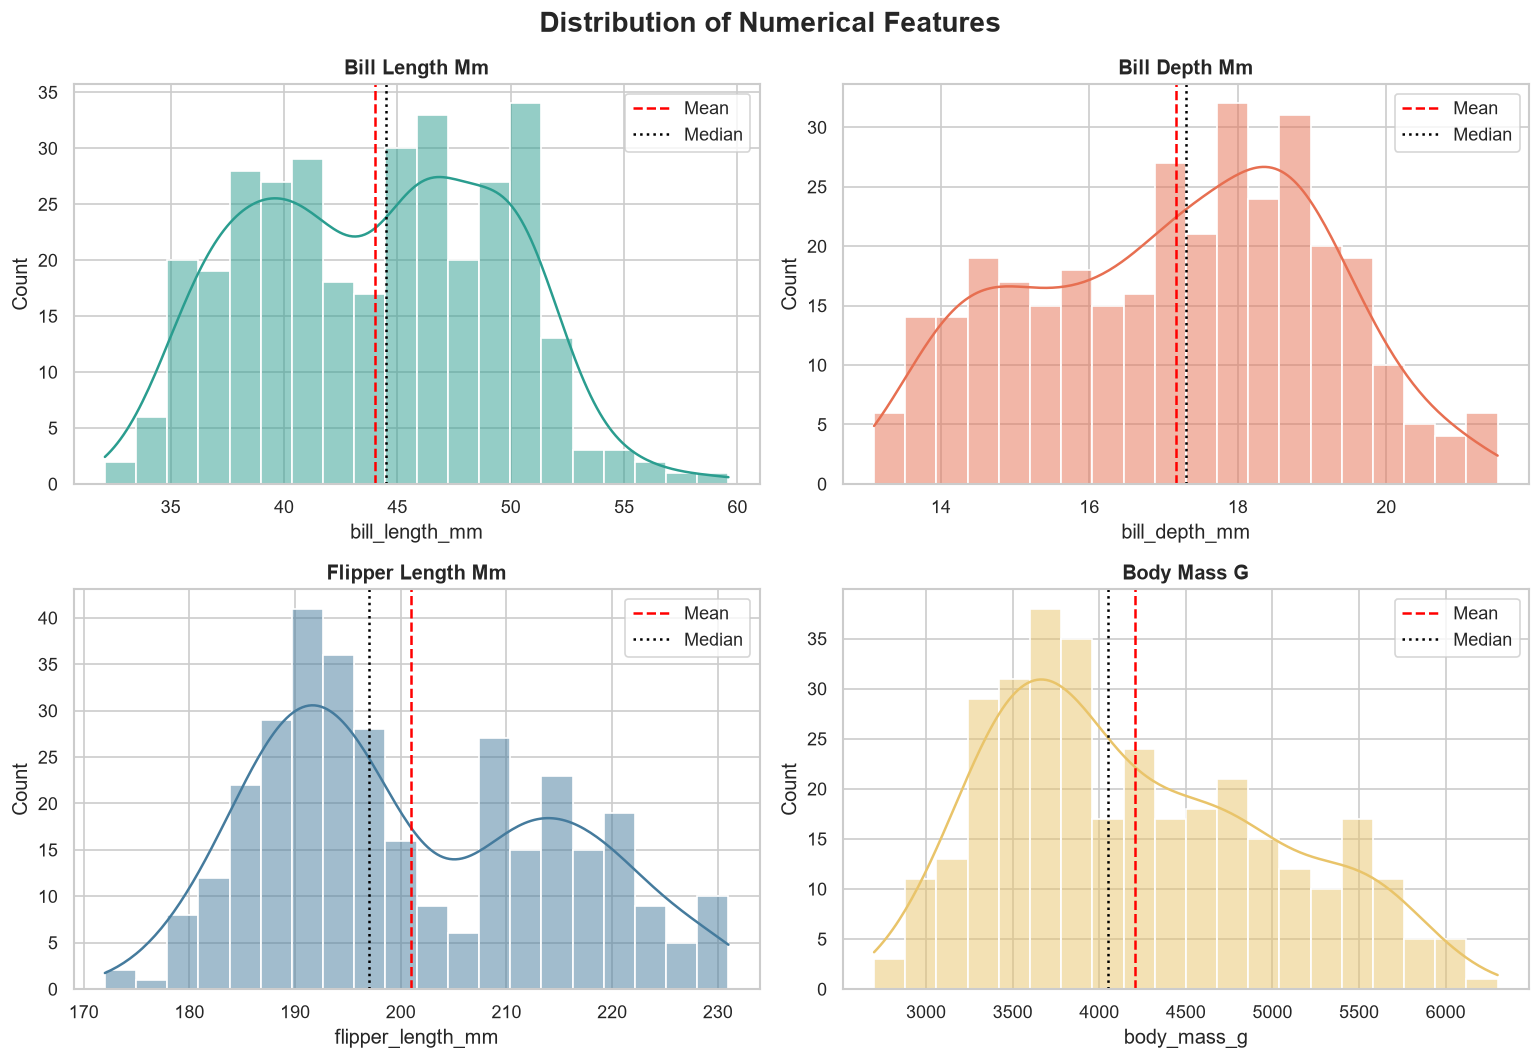

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

colors = [
    "#2A9D8F",
    "#E76F51",
    "#457B9D",
    "#E9C46A"
]

for ax, col, color in zip(
    axes.flatten(), numeric_cols, colors
):
    sns.histplot(
        data=df_clean,
        x=col,
        kde=True,
        bins=20,
        color=color,
        ax=ax
    )

    ax.set_title(
        col.replace("_", " ").title(),
        fontweight="bold"
    )

    ax.axvline(
        df_clean[col].mean(),
        color="red",
        linestyle="--",
        label="Mean"
    )

    ax.axvline(
        df_clean[col].median(),
        color="black",
        linestyle=":",
        label="Median"
    )

    ax.legend()

fig.suptitle(
    "Distribution of Numerical Features",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "numerical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Key Insights

- Bill length and bill depth exhibit variation across
  the observed penguins.
- Flipper length and body mass show patterns consistent
  with the presence of multiple groups.
- The distributions are not necessarily normally distributed.
- Differences in physical characteristics may provide
  useful information for species classification.
- Species-wise analysis is required to understand the
  origin of these distribution patterns.

### 8.1.5 Outlier Detection Using Box Plots

Box plots are used to examine the median, quartiles,
interquartile range and potential outliers.

The Interquartile Range (IQR) method identifies values
outside the following boundaries:

- Lower Bound = Q1 - 1.5 × IQR
- Upper Bound = Q3 + 1.5 × IQR

Potential outliers are investigated before making any
decision regarding their removal.

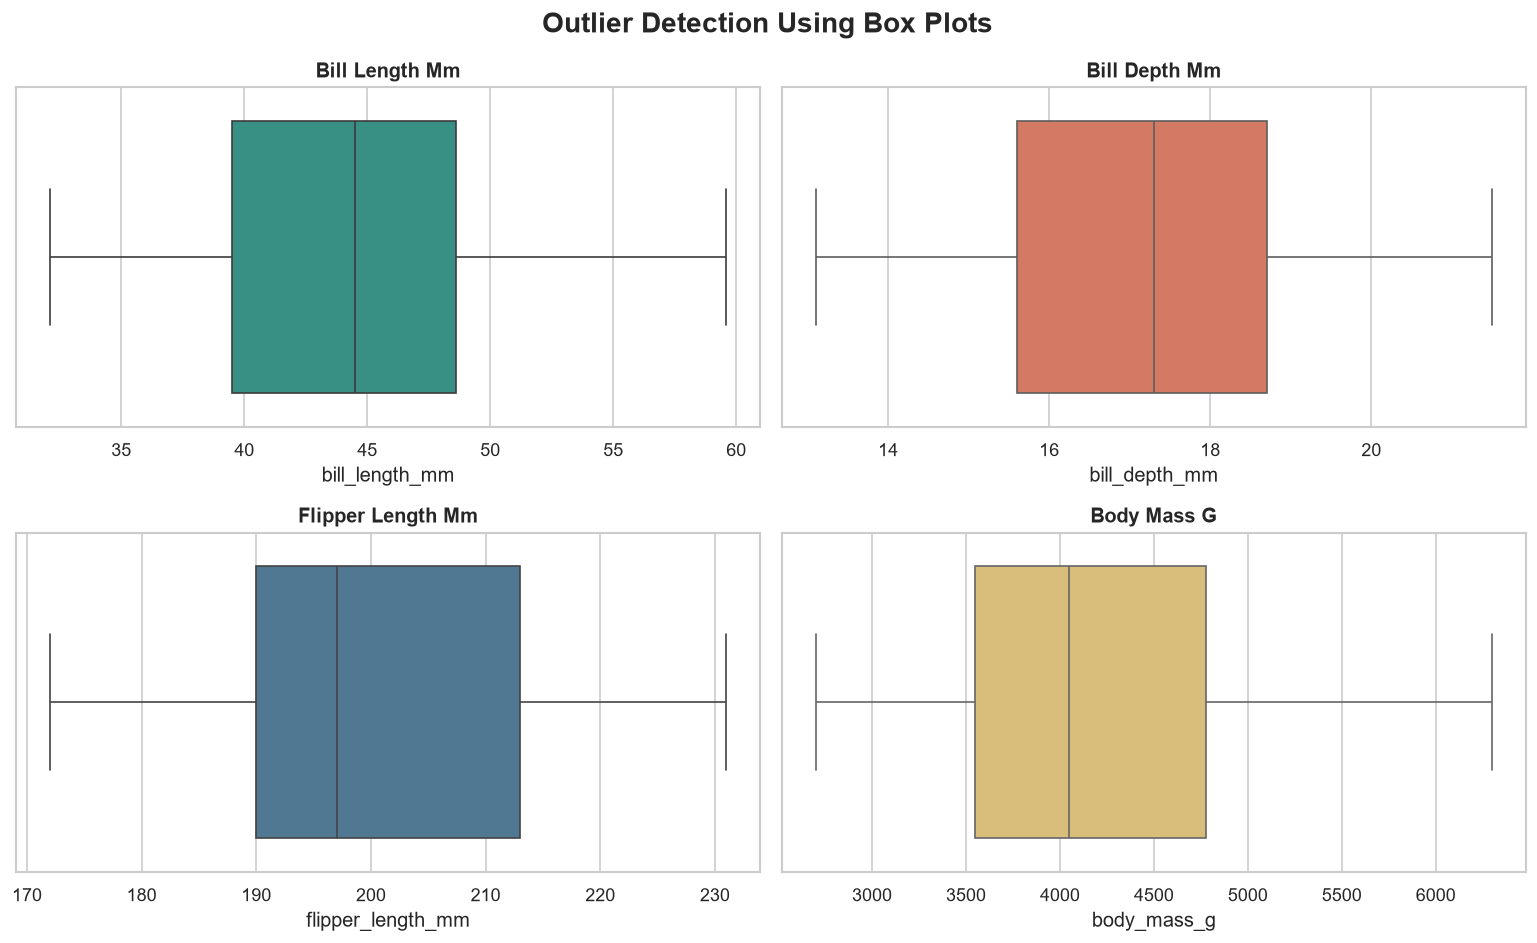

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, col, color in zip(
    axes.flatten(), numeric_cols, colors
):
    sns.boxplot(
        data=df_clean,
        x=col,
        color=color,
        ax=ax
    )

    ax.set_title(
        col.replace("_", " ").title(),
        fontweight="bold"
    )

fig.suptitle(
    "Outlier Detection Using Box Plots",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "outlier_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
outlier_report = []

for col in numeric_cols:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    outlier_report.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

pd.DataFrame(outlier_report).round(2)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,bill_length_mm,39.5,48.6,9.1,25.85,62.25,0
1,bill_depth_mm,15.6,18.7,3.1,10.95,23.35,0
2,flipper_length_mm,190.0,213.0,23.0,155.50,247.50,0
3,body_mass_g,3550.0,4775.0,1225.0,1712.50,6612.50,0


#### Key Insights

- The overall IQR method does not identify extreme
  outliers in the numerical features.
- Physical measurements exhibit natural biological variation.
- No observations are removed during outlier analysis.
- Species-specific outlier analysis may reveal additional
  patterns that are not visible in the overall distribution.

## 9. Data Cleaning and Univariate Analysis Summary

The dataset was successfully cleaned and explored using
descriptive statistics and univariate visualizations.

### Major Findings

1. The cleaned dataset contains 333 observations.
2. Missing values and duplicate records have been addressed.
3. Adelie is the most frequently represented species.
4. Biscoe Island contains the highest number of observations.
5. Male and female penguins are almost equally represented.
6. Numerical features exhibit meaningful biological variation.
7. No extreme outliers were identified using the overall
   IQR method.

### Next Steps

Bivariate and multivariate analysis will be performed
to investigate relationships between physical features
and penguin species.

These findings will support feature selection and
machine learning model development.

In [25]:
print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicates:", df_clean.duplicated().sum())
print("Saved visualizations:", len(list(VISUAL_DIR.glob("*.png"))))

Dataset shape: (333, 7)
Missing values: 0
Duplicates: 0
Saved visualizations: 19


## 10. Bivariate Analysis

Bivariate analysis examines the relationship between
two variables to identify associations, differences
and meaningful patterns.

### Objectives

- Compare physical characteristics across penguin species.
- Examine relationships between numerical features.
- Understand species distribution across islands.
- Investigate differences in categorical variables.
- Identify potentially important features for
  machine learning classification.

### Visualization Techniques

- Box plots
- Violin plots
- Scatter plots
- Grouped bar charts
- Cross-tabulation

In [26]:
species_order = ["Adelie", "Chinstrap", "Gentoo"]

species_palette = {
    "Adelie": "#66C2A5",
    "Chinstrap": "#FC8D62",
    "Gentoo": "#8DA0CB"
}

### 10.1 Species-wise Descriptive Statistics

Research Question:

How do the average physical measurements differ
among the three penguin species?

Grouped statistical analysis is performed to compare
the physical characteristics of Adelie, Chinstrap
and Gentoo penguins.

In [27]:
species_summary = df_clean.groupby("species")[
    numeric_cols
].mean().round(2)

species_summary

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.82,18.35,190.10,3706.16
Chinstrap,48.83,18.42,195.82,3733.09
Gentoo,47.57,15.00,217.24,5092.44


In [28]:
species_summary.style.background_gradient(
    cmap="YlGnBu",
    axis=0
).format("{:.2f}")

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.82,18.35,190.10,3706.16
Chinstrap,48.83,18.42,195.82,3733.09
Gentoo,47.57,15.00,217.24,5092.44


#### Key Insights

- Gentoo penguins have the highest average body mass
  and flipper length.
- Chinstrap penguins have the highest average bill length.
- Adelie penguins have comparatively shorter bills.
- Gentoo penguins have a lower average bill depth
  than the other two species.
- Physical measurements demonstrate species-specific
  differences that may support classification.

### 10.2 Relationship Between Species and Body Mass

Research Question:

Does body mass differ significantly across the
three penguin species?

A box plot is used to compare the distribution,
median, spread and potential outliers of body mass
across species.

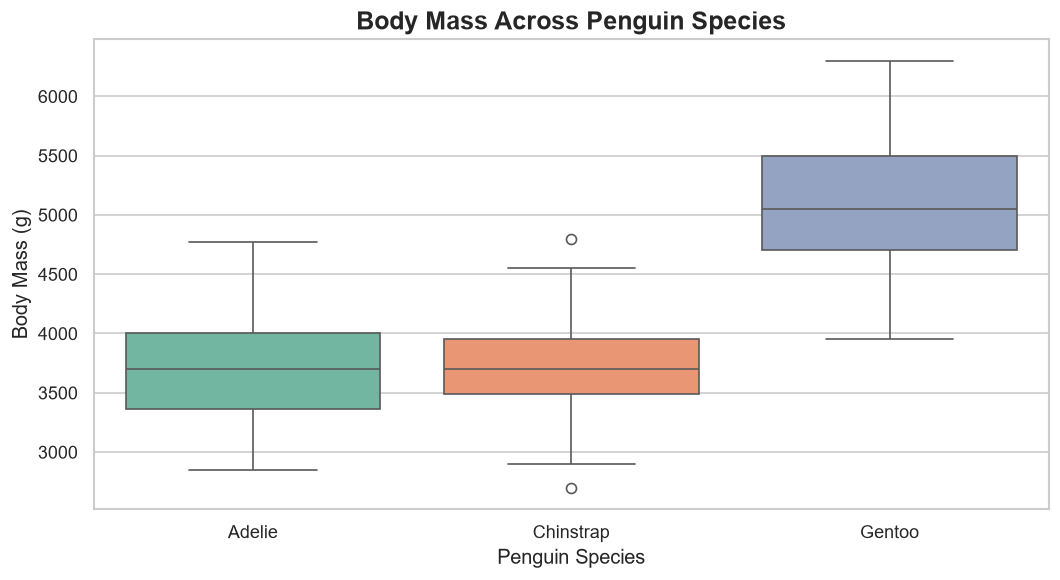

In [29]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="species",
    y="body_mass_g",
    hue="species",
    order=species_order,
    palette=species_palette,
    legend=False
)

plt.title(
    "Body Mass Across Penguin Species",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Penguin Species")
plt.ylabel("Body Mass (g)")

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "species_vs_body_mass.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Key Insights

- Gentoo penguins generally have a higher body mass
  than Adelie and Chinstrap penguins.
- Adelie and Chinstrap penguins show considerable
  overlap in their body mass distributions.
- Body mass may help distinguish Gentoo penguins
  from the other species.
- Body mass alone may not be sufficient to distinguish
  Adelie from Chinstrap penguins.

### 10.3 Relationship Between Species and Flipper Length

Research Question:

Can flipper length help distinguish different
penguin species?

A violin plot is used to visualize the distribution
and density of flipper length across species.

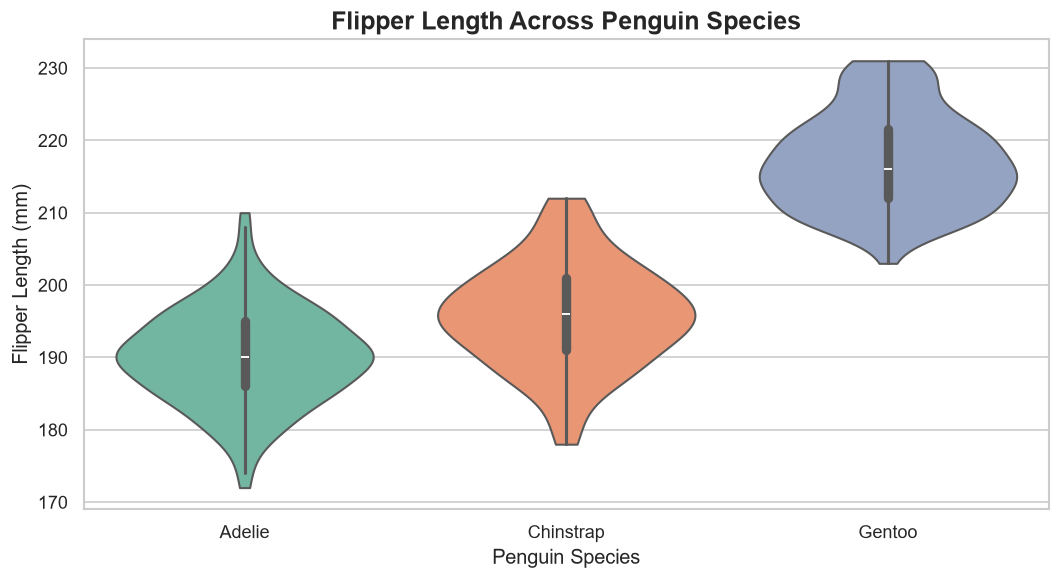

In [30]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df_clean,
    x="species",
    y="flipper_length_mm",
    hue="species",
    order=species_order,
    palette=species_palette,
    inner="box",
    cut=0,
    legend=False
)

plt.title(
    "Flipper Length Across Penguin Species",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Penguin Species")
plt.ylabel("Flipper Length (mm)")

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "species_vs_flipper_length.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Key Insights

- Gentoo penguins generally have longer flippers.
- Adelie penguins have comparatively shorter flippers.
- Chinstrap penguins show intermediate flipper lengths.
- Flipper length appears to be a promising feature
  for distinguishing Gentoo penguins.
- Model-based analysis is required to confirm its
  predictive importance.

### 10.4 Comparison of Bill Measurements Across Species

Research Question:

How do bill length and bill depth vary across
penguin species?

Comparative box plots are used to examine differences
in bill measurements and assess their potential
usefulness for species classification.

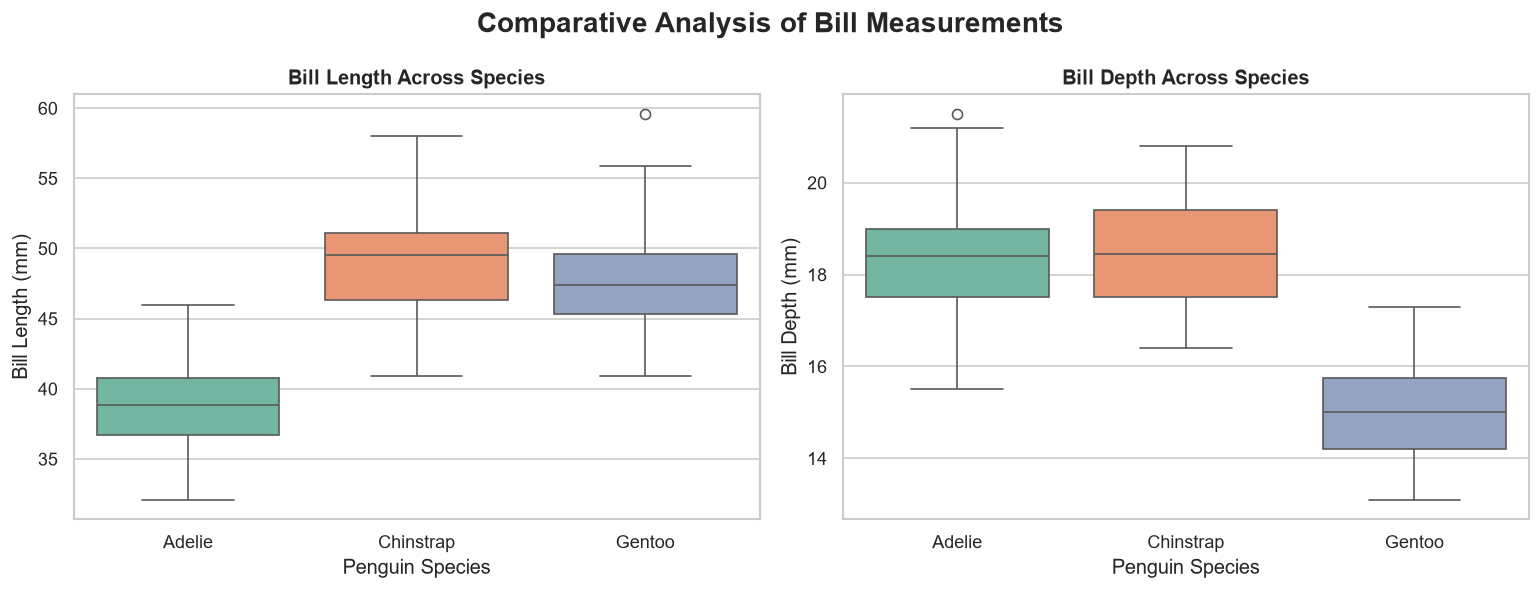

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

features = ["bill_length_mm", "bill_depth_mm"]

titles = [
    "Bill Length Across Species",
    "Bill Depth Across Species"
]

labels = [
    "Bill Length (mm)",
    "Bill Depth (mm)"
]

for ax, col, title, label in zip(
    axes, features, titles, labels
):

    sns.boxplot(
        data=df_clean,
        x="species",
        y=col,
        hue="species",
        order=species_order,
        palette=species_palette,
        legend=False,
        ax=ax
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Penguin Species")
    ax.set_ylabel(label)

fig.suptitle(
    "Comparative Analysis of Bill Measurements",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "bill_measurements_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Key Insights

- Adelie penguins generally have shorter bills.
- Chinstrap penguins have the highest average bill length.
- Gentoo penguins have comparatively shallow bills.
- Adelie and Chinstrap penguins show overlap in bill depth.
- Combining bill length and bill depth may provide
  better species separation than using either feature alone.

### 10.5 Relationship Between Bill Length and Bill Depth

Research Question:

Can the combination of bill length and bill depth
visually distinguish penguin species?

A scatter plot is used to examine the relationship
between the two numerical features, with different
colors representing penguin species.

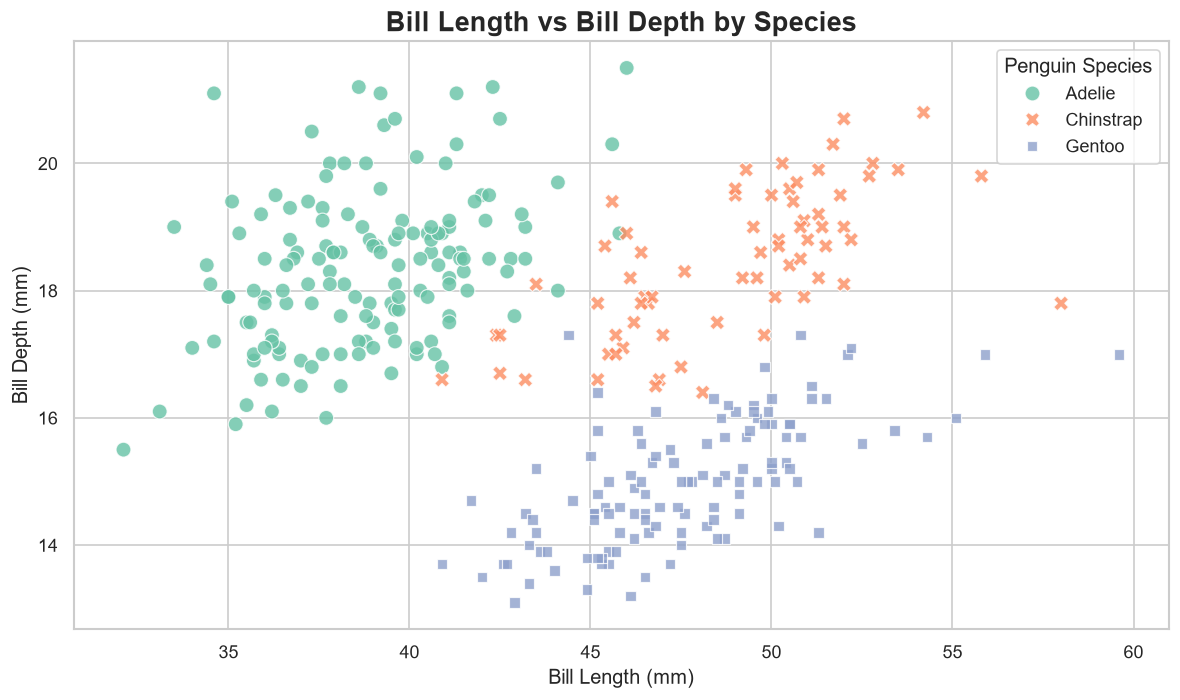

In [32]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species",
    style="species",
    hue_order=species_order,
    palette=species_palette,
    s=80,
    alpha=0.8
)

plt.title(
    "Bill Length vs Bill Depth by Species",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.legend(title="Penguin Species")

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "bill_length_vs_bill_depth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Key Insights

- The three species form visually distinguishable groups.
- Adelie penguins generally have shorter bills.
- Chinstrap penguins generally have longer and deeper bills.
- Gentoo penguins generally have longer but shallower bills.
- Some overlap exists between species.
- The combination of bill length and bill depth
  demonstrates promising discriminatory potential.

### 10.6 Relationship Between Flipper Length and Body Mass

Research Question:

Do penguins with longer flippers generally have
greater body mass?

A scatter plot and Pearson correlation coefficient
are used to examine the relationship between
flipper length and body mass.

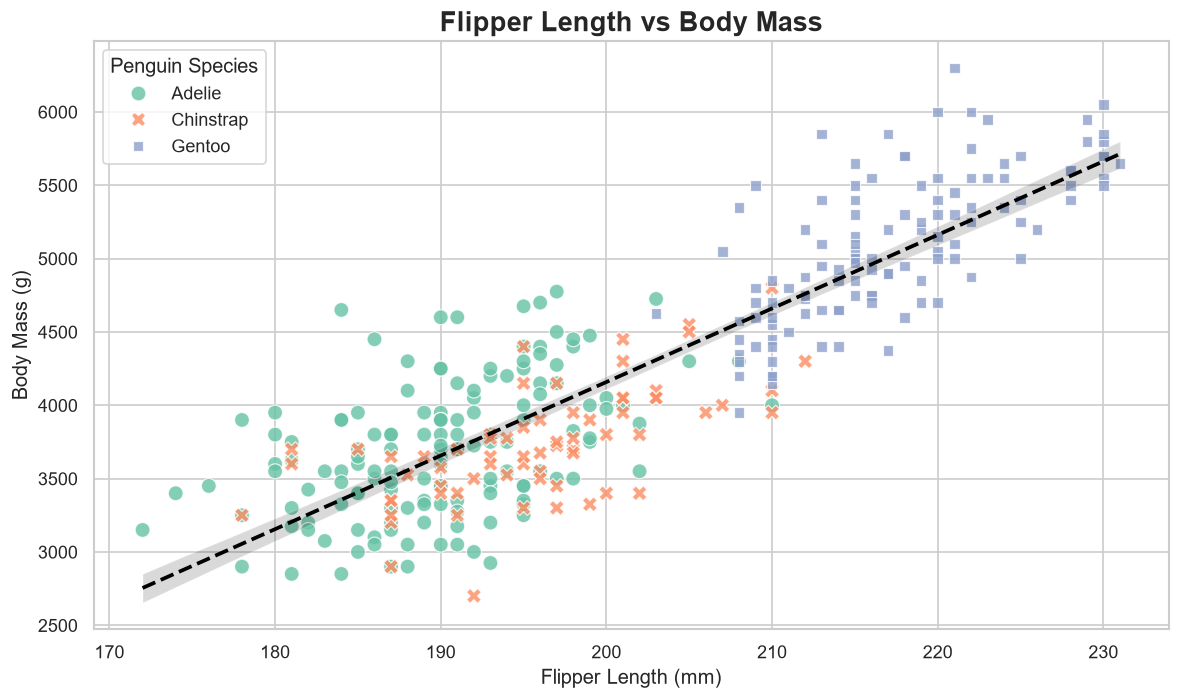

In [33]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    style="species",
    hue_order=species_order,
    palette=species_palette,
    s=80,
    alpha=0.8
)

sns.regplot(
    data=df_clean,
    x="flipper_length_mm",
    y="body_mass_g",
    scatter=False,
    color="black",
    line_kws={"linestyle": "--"}
)

plt.title(
    "Flipper Length vs Body Mass",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")
plt.legend(title="Penguin Species")

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "flipper_length_vs_body_mass.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
correlation = df_clean[
    "flipper_length_mm"
].corr(df_clean["body_mass_g"])

print("Pearson Correlation:",
      round(correlation, 3))

Pearson Correlation: 0.873


#### Key Insights

- Flipper length and body mass exhibit a strong
  positive correlation of approximately 0.873.
- Penguins with longer flippers generally have
  greater body mass.
- Gentoo penguins are concentrated toward higher
  values of both measurements.
- Differences between species may contribute to
  the overall correlation.
- Correlation does not establish causation.

### 10.7 Relationship Between Species and Island

Research Question:

Are different penguin species distributed equally
across the three islands?

Cross-tabulation and grouped bar charts are used
to examine the relationship between species
and geographical location.

In [35]:
island_species = pd.crosstab(
    df_clean["island"],
    df_clean["species"]
)

island_species

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,119
Dream,55,68,0
Torgersen,47,0,0


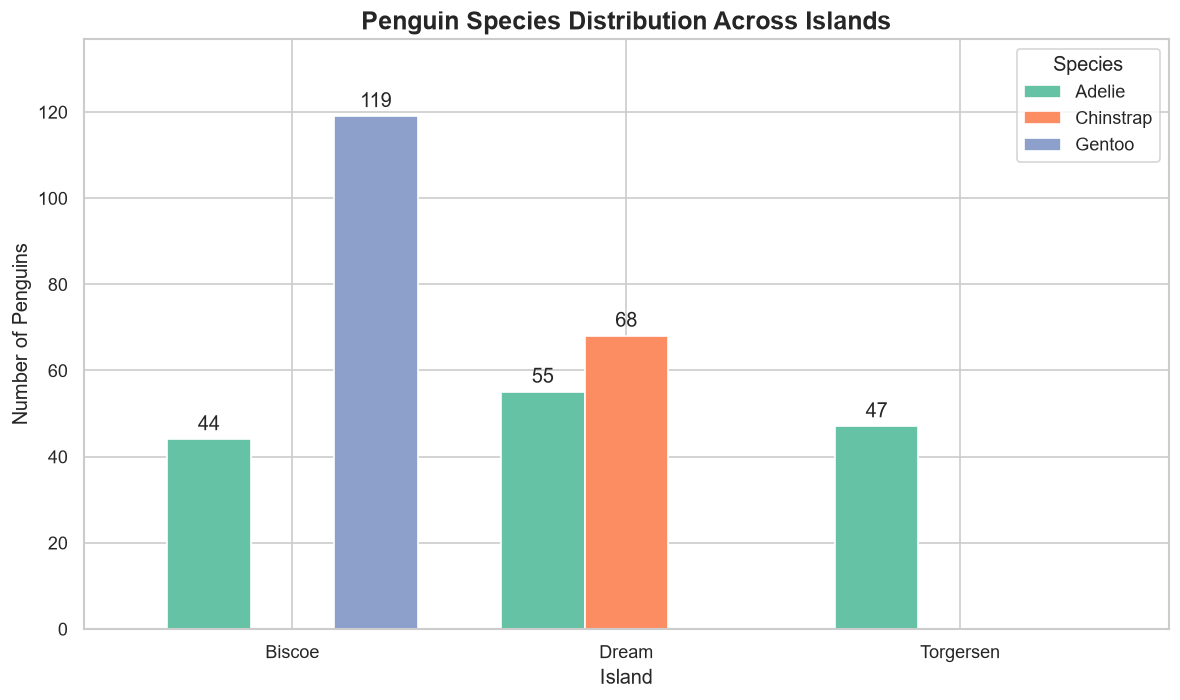

In [36]:
ax = island_species.plot(
    kind="bar",
    figsize=(10, 6),
    color=[
        species_palette[col]
        for col in island_species.columns
    ],
    width=0.75
)

for container in ax.containers:
    labels = [
        f"{int(v)}" if v > 0 else ""
        for v in container.datavalues
    ]

    ax.bar_label(
        container,
        labels=labels,
        padding=3
    )

plt.title(
    "Penguin Species Distribution Across Islands",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Island")
plt.ylabel("Number of Penguins")
plt.xticks(rotation=0)
plt.ylim(0, island_species.max().max() * 1.15)
plt.legend(title="Species")

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "species_vs_island.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Key Insights

- Adelie penguins are represented on all three islands.
- Chinstrap penguins are observed only on Dream Island
  within this dataset.
- Gentoo penguins are observed only on Biscoe Island
  within this dataset.
- Island and species show a strong association.
- These observations describe the collected samples
  and should not be generalized to all penguin populations.

### Feature Selection Consideration

Island is excluded from the primary classification
model to reduce reliance on geographical associations
and encourage classification based on physical
measurements.

### 10.8 Relationship Between Species and Sex

Research Question:

Is the distribution of male and female penguins
balanced within each species?

Cross-tabulation and stacked bar charts are used
to compare sex distribution across species.

In [37]:
species_sex = pd.crosstab(
    df_clean["species"],
    df_clean["sex"]
)

species_sex

sex,Female,Male
species,,
Adelie,73,73
Chinstrap,34,34
Gentoo,58,61


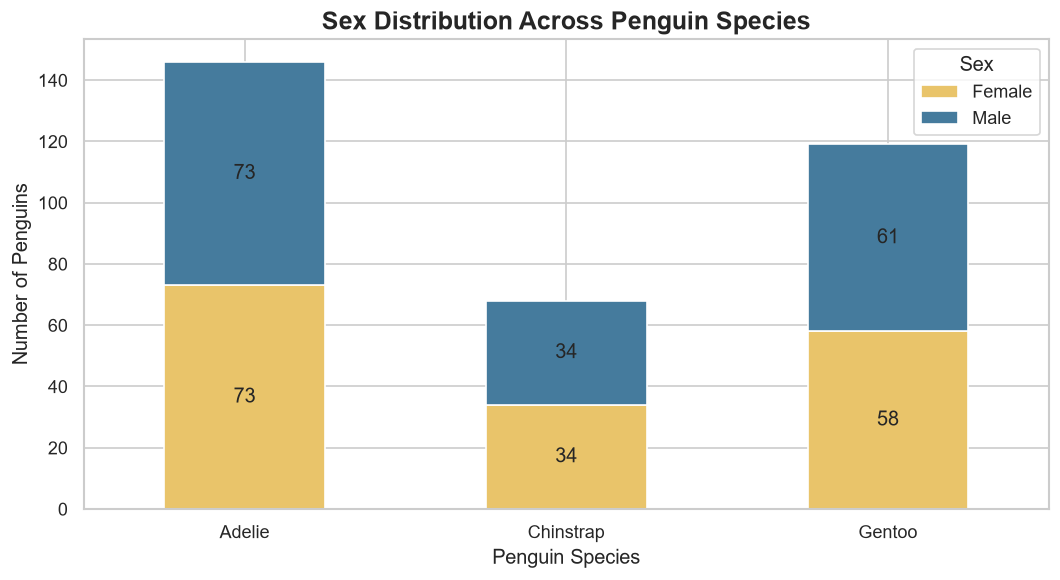

In [38]:
ax = species_sex.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#E9C46A", "#457B9D"]
)

for container in ax.containers:
    ax.bar_label(
        container,
        label_type="center"
    )

plt.title(
    "Sex Distribution Across Penguin Species",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Penguin Species")
plt.ylabel("Number of Penguins")
plt.xticks(rotation=0)
plt.legend(title="Sex")

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "species_vs_sex.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Key Insights

- Adelie penguins have an equal distribution
  of male and female observations.
- Chinstrap penguins also have equal representation.
- Gentoo penguins have a slightly higher number
  of male observations.
- No substantial sex imbalance is observed
  within the three species.

## 11. Bivariate Analysis Summary

Bivariate analysis revealed meaningful relationships
between penguin species, physical measurements
and geographical characteristics.

### Major Findings

1. Gentoo penguins have the highest average body mass
   and flipper length.

2. Chinstrap penguins have the highest average bill length.

3. Adelie penguins generally have shorter bills
   and shorter flippers.

4. Bill length and bill depth together demonstrate
   promising species separation.

5. Flipper length and body mass exhibit a strong
   positive correlation.

6. Penguin species show a strong association
   with island of observation.

7. Male and female observations are approximately
   balanced within each species.

### Implications for Machine Learning

The following physical measurements are identified
as promising predictor variables:

- Bill length
- Bill depth
- Flipper length
- Body mass

Their predictive usefulness will be evaluated through
machine learning model training and validation.

### Next Steps

Multivariate analysis will be performed to examine
relationships among multiple features simultaneously,
followed by machine learning model development.

In [39]:
print("Dataset shape:", df_clean.shape)

print("Total saved visualizations:",
      len(list(VISUAL_DIR.glob("*.png"))))

print("\nSaved files:")

for file in sorted(VISUAL_DIR.glob("*.png")):
    print(file.name)

Dataset shape: (333, 7)
Total saved visualizations: 19

Saved files:
bill_length_vs_bill_depth.png
bill_measurements_comparison.png
confusion_matrix.png
correlation_heatmap.png
feature_importance.png
flipper_length_vs_body_mass.png
island_distribution.png
missing_values.png
model_comparison.png
numerical_distributions.png
outlier_analysis.png
pairplot_analysis.png
sex_distribution.png
species_correlation_heatmaps.png
species_distribution.png
species_vs_body_mass.png
species_vs_flipper_length.png
species_vs_island.png
species_vs_sex.png


## 12. Multivariate Analysis

Multivariate analysis examines multiple variables
simultaneously to identify complex relationships,
dependencies and patterns within the dataset.

### Objectives

- Identify correlations among numerical features.
- Examine species separation across multiple measurements.
- Investigate relationships within individual species.
- Identify suitable predictor variables.
- Support machine learning model development.

### Techniques Used

- Pearson correlation matrix
- Correlation heatmap
- Pair plot
- Species-specific correlation analysis

### 12.1 Correlation Analysis

Research Question:

How strongly are the numerical features related
to one another?

Pearson correlation is used to measure the strength
and direction of linear relationships between
numerical variables.

A heatmap provides a visual representation of
the correlation matrix.

In [40]:
correlation_matrix = df_clean[numeric_cols].corr()

correlation_matrix.round(3)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000,-0.229,0.653,0.589
bill_depth_mm,-0.229,1.000,-0.578,-0.472
flipper_length_mm,0.653,-0.578,1.000,0.873
body_mass_g,0.589,-0.472,0.873,1.000


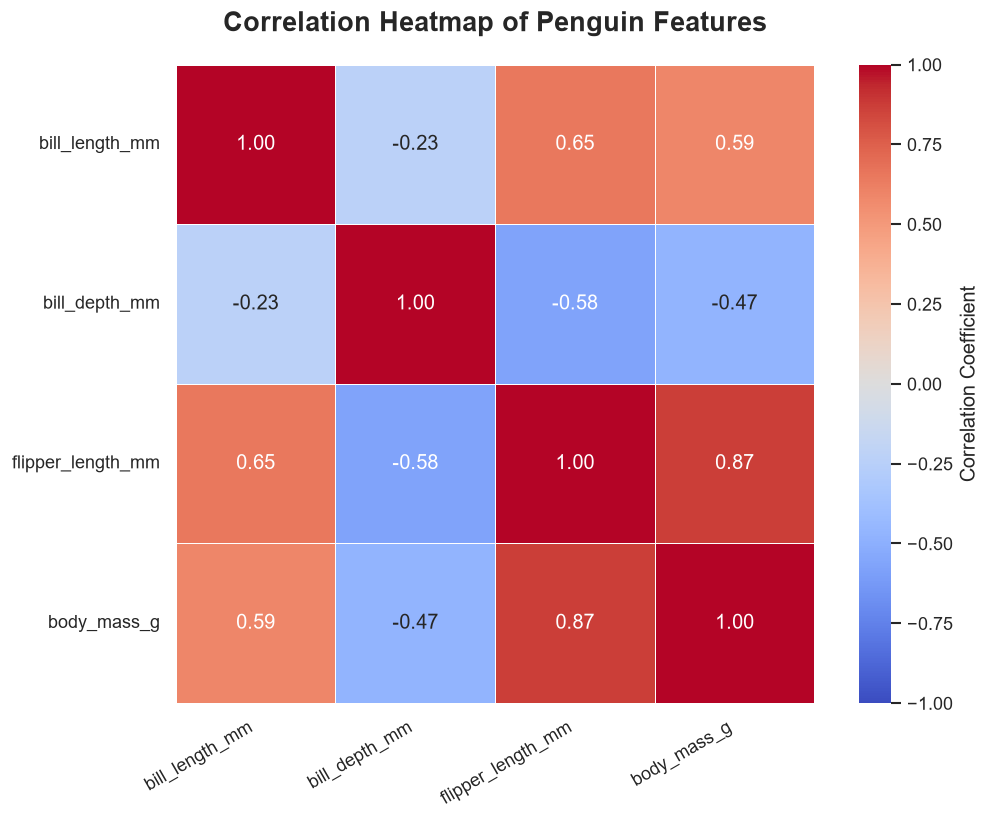

In [41]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlation Coefficient"}
)

plt.title(
    "Correlation Heatmap of Penguin Features",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Key Insights

- Flipper length and body mass exhibit the strongest
  positive correlation of approximately 0.87.

- Bill length shows a positive correlation with
  flipper length and body mass.

- Bill depth shows negative correlations with
  flipper length and body mass.

- Some numerical features contain overlapping information.

- Correlation between predictors does not necessarily
  indicate that a feature should be removed.

- Model performance will be evaluated before making
  final feature selection decisions.

### 12.2 Pairwise Feature Relationship Analysis

Research Question:

Can combinations of physical measurements distinguish
the three penguin species?

A pair plot is used to visualize pairwise relationships
between numerical features and their individual
distributions.

Different colors represent different penguin species,
allowing visual identification of clusters and
overlapping observations.

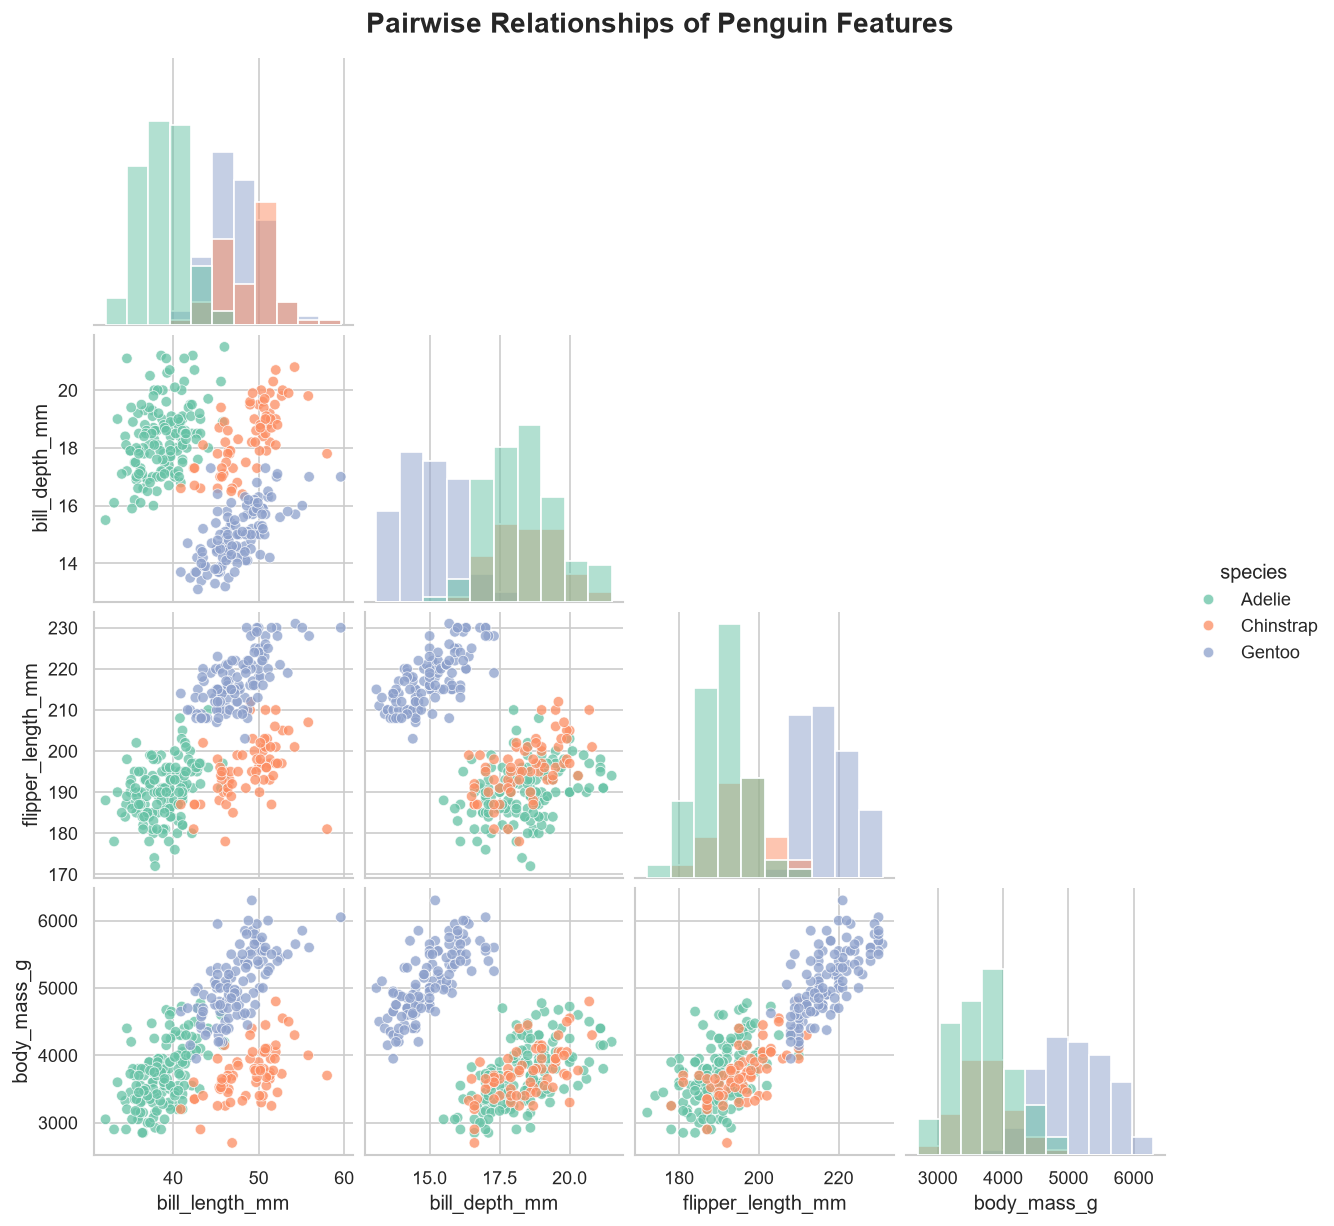

In [42]:
pair_plot = sns.pairplot(
    data=df_clean,
    vars=numeric_cols,
    hue="species",
    hue_order=species_order,
    palette=species_palette,
    diag_kind="hist",
    corner=True,
    height=2.5,
    plot_kws={
        "alpha": 0.75,
        "s": 40
    }
)

pair_plot.fig.suptitle(
    "Pairwise Relationships of Penguin Features",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

pair_plot.savefig(
    VISUAL_DIR / "pairplot_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Key Insights

- Gentoo penguins form relatively distinct clusters
  in several feature combinations.

- Adelie and Chinstrap penguins exhibit some overlap
  in body mass and flipper length.

- Bill measurements provide useful separation between
  Adelie and Chinstrap penguins.

- Combining multiple physical measurements provides
  better visual separation than relying on a single
  feature.

- The observed patterns suggest that supervised
  classification algorithms may perform well on
  this dataset.

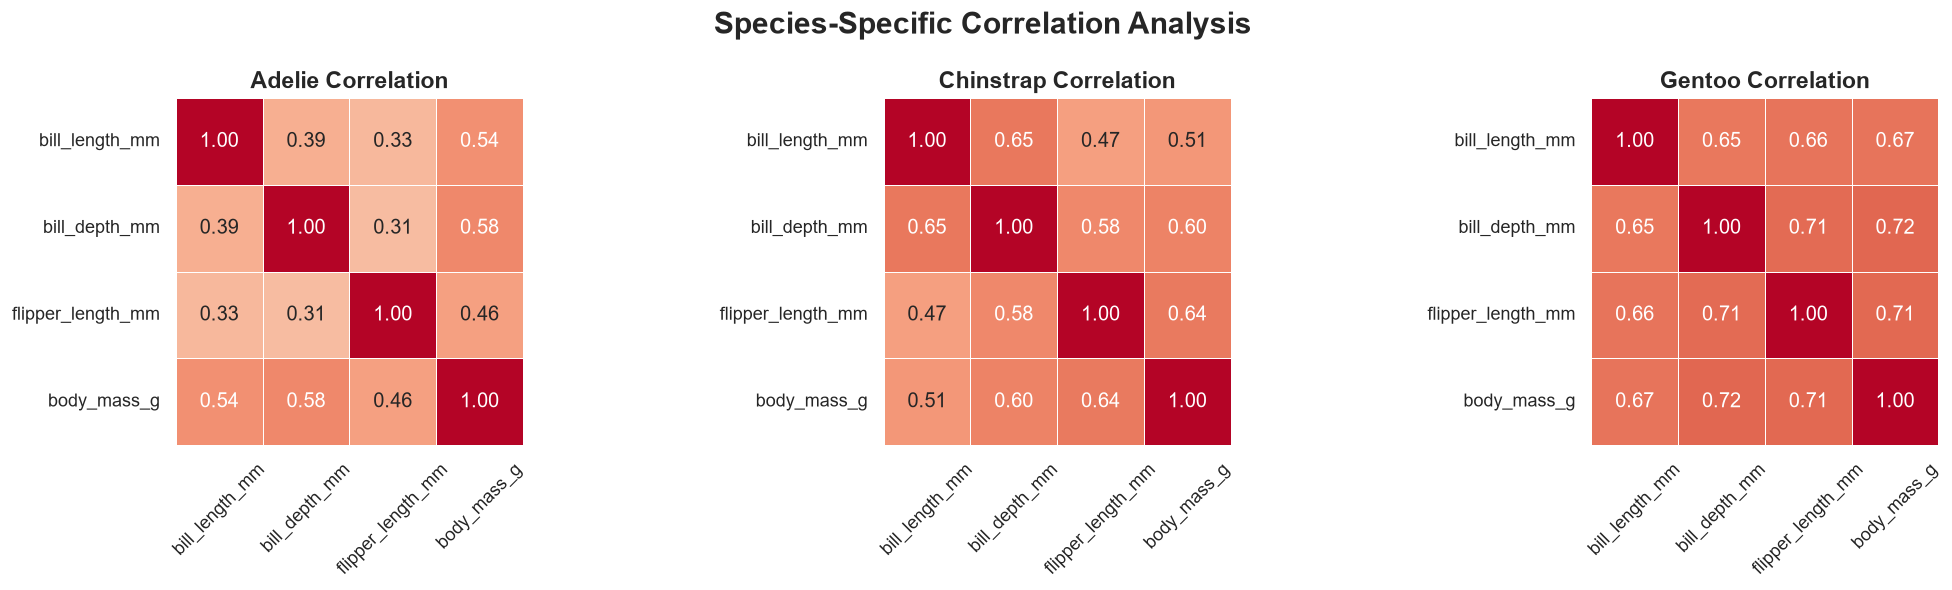

In [43]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, species in zip(axes, species_order):

    species_data = df_clean[
        df_clean["species"] == species
    ]

    species_corr = species_data[numeric_cols].corr()

    sns.heatmap(
        species_corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5,
        cbar=False,
        ax=ax
    )

    ax.set_title(
        f"{species} Correlation",
        fontsize=14,
        fontweight="bold"
    )

    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle(
    "Species-Specific Correlation Analysis",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "species_correlation_heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [44]:
correlation_results = []

for species in species_order:

    subset = df_clean[
        df_clean["species"] == species
    ]

    corr = subset["flipper_length_mm"].corr(
        subset["body_mass_g"]
    )

    correlation_results.append({
        "Species": species,
        "Correlation": corr
    })

correlation_results.append({
    "Species": "Overall",
    "Correlation": df_clean["flipper_length_mm"].corr(
        df_clean["body_mass_g"]
    )
})

correlation_comparison = pd.DataFrame(
    correlation_results
)

correlation_comparison.round(3)

,Species,Correlation
0,Adelie,0.465
1,Chinstrap,0.642
2,Gentoo,0.711
3,Overall,0.873


#### Key Insights

- Correlation patterns vary across penguin species.

- Flipper length and body mass demonstrate positive
  relationships within individual species.

- The overall correlation is stronger than the
  individual species correlations.

- Differences between species contribute to the
  relationships observed in the combined dataset.

- Group-level analysis provides additional context
  that may be overlooked in overall analysis.

## 13. Feature Selection

Feature selection involves identifying relevant
predictor variables for machine learning model
development.

Based on exploratory data analysis, four physical
measurements are selected as the primary predictors.

### Selected Features

| Feature | Reason for Selection |
|---|---|
| bill_length_mm | Helps distinguish species based on bill size |
| bill_depth_mm | Captures differences in bill structure |
| flipper_length_mm | Provides information about species-specific size |
| body_mass_g | Helps distinguish heavier and lighter species |

### Excluded Features

| Feature | Reason for Exclusion |
|---|---|
| island | Reduces dependence on geographical associations |
| sex | Supports a simpler measurement-based model |

### Target Variable

The target variable is `species`, which contains
three classes: Adelie, Chinstrap and Gentoo.

The predictive usefulness of the selected features
will be evaluated during model development.

In [45]:
feature_cols = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

target_col = "species"

print("Selected features:")

for feature in feature_cols:
    print("-", feature)

print("\nTarget variable:", target_col)

print("Number of features:", len(feature_cols))

print("Number of classes:",
      df[target_col].nunique())

Selected features:
- bill_length_mm
- bill_depth_mm
- flipper_length_mm
- body_mass_g

Target variable: species
Number of features: 4
Number of classes: 3


## 14. Exploratory Data Analysis — Final Conclusion

The Palmer Penguins dataset was systematically
explored through data quality assessment, descriptive
statistics, univariate, bivariate and multivariate
analysis.

### Data Quality Findings

- The original dataset contains 344 observations
  and seven columns.
- The complete-case dataset contains 333 observations.
- Approximately 96.80% of the original data is retained.
- No missing values or duplicate records remain
  in the cleaned dataset.

### Species-Level Findings

- Adelie is the most frequently represented species.
- Gentoo penguins have the highest average body mass
  and flipper length.
- Chinstrap penguins have the highest average bill length.
- Adelie penguins generally have shorter bills.
- Gentoo penguins have comparatively shallow bills.

### Statistical Findings

- Flipper length and body mass demonstrate a strong
  positive correlation.
- Correlation patterns vary across individual species.
- Physical measurements demonstrate meaningful
  species-specific differences.
- Combining multiple measurements provides promising
  visual separation between species.

### Geographical Findings

- Adelie penguins are represented on all three islands.
- Chinstrap penguins are observed on Dream Island.
- Gentoo penguins are observed on Biscoe Island.
- These findings describe the sampled observations
  rather than the entire penguin population.

### Limitations

- The dataset contains a relatively small sample size.
- Observations are limited to three penguin species
  and three islands.
- Complete-case analysis may introduce selection bias.
- Correlation does not establish causation.
- Visual species separation does not guarantee
  high predictive performance on unseen data.

### Final EDA Conclusion

The exploratory analysis indicates that physical
measurements contain useful information for
distinguishing penguin species.

The next stage involves developing and evaluating
supervised machine learning classification models
using these measurements.

In [46]:
print("EDA completed successfully!")

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

print("Selected features:", len(feature_cols))

print("Total visualizations:",
      len(list(VISUAL_DIR.glob("*.png"))))

print("\nVisualization files:")

for file in sorted(VISUAL_DIR.glob("*.png")):
    print(file.name)

EDA completed successfully!
Original dataset: (344, 7)
Cleaned dataset: (333, 7)
Selected features: 4
Total visualizations: 19

Visualization files:
bill_length_vs_bill_depth.png
bill_measurements_comparison.png
confusion_matrix.png
correlation_heatmap.png
feature_importance.png
flipper_length_vs_body_mass.png
island_distribution.png
missing_values.png
model_comparison.png
numerical_distributions.png
outlier_analysis.png
pairplot_analysis.png
sex_distribution.png
species_correlation_heatmaps.png
species_distribution.png
species_vs_body_mass.png
species_vs_flipper_length.png
species_vs_island.png
species_vs_sex.png


## 15. Machine Learning — Species Classification

The objective of this section is to develop a supervised
machine learning model capable of predicting penguin
species using physical measurements.

### Problem Type

Supervised Learning — Multiclass Classification

### Target Classes

- Adelie
- Chinstrap
- Gentoo

### Machine Learning Models

1. Dummy Classifier (Baseline)
2. Logistic Regression
3. K-Nearest Neighbors
4. Decision Tree
5. Random Forest

### Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix
- Stratified Cross-Validation

The models will be compared using cross-validation
on the training dataset. The selected model will
then be evaluated on the held-out test dataset.

### 15.1 Importing Machine Learning Libraries

Scikit-learn provides tools for data preprocessing,
model development, cross-validation and classification
performance evaluation.

In [47]:
# Data splitting and validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

# Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Classification algorithms
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Feature importance
from sklearn.inspection import permutation_importance

# Model persistence
import joblib

### 15.2 Feature and Target Preparation

The four physical measurements identified during
exploratory data analysis are used as predictor variables.

The original dataset is used for machine learning to
retain observations with missing values in non-selected
features.

Missing numerical measurements will be handled within
the preprocessing pipeline.

The target variable is penguin species.

In [48]:
feature_cols = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

target_col = "species"

df_ml = df.dropna(
    subset=[target_col]
).copy()

X = df_ml[feature_cols]
y = df_ml[target_col]

print("Feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (344, 4)
Target variable shape: (344,)

Target distribution:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


### 15.3 Train-Test Split

The dataset is divided into training and testing
subsets using an 80:20 ratio.

Stratified sampling is applied to preserve the
proportion of each penguin species in both subsets.

A fixed random state ensures reproducibility.

In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (275, 4)
Testing features: (69, 4)
Training target: (275,)
Testing target: (69,)


In [50]:
split_distribution = pd.DataFrame({
    "Original (%)": y.value_counts(normalize=True) * 100,
    "Training (%)": y_train.value_counts(normalize=True) * 100,
    "Testing (%)": y_test.value_counts(normalize=True) * 100
})

split_distribution.round(2)

,Original (%),Training (%),Testing (%)
species,,,
Adelie,44.19,44.36,43.48
Gentoo,36.05,36.00,36.23
Chinstrap,19.77,19.64,20.29


### 15.4 Data Preprocessing

Machine learning algorithms require appropriate
preprocessing of input features.

The preprocessing techniques used are:

#### Median Imputation

Missing numerical values are replaced with the median
calculated from the training data.

#### Standardization

Numerical features are transformed to comparable scales
using StandardScaler where required.

#### Pipeline

Preprocessing and model training are combined using
Scikit-learn pipelines to prevent preprocessing-related
data leakage and improve reproducibility.

### 15.5 Model Development

Five classification algorithms are implemented.

A Dummy Classifier establishes baseline performance.
Logistic Regression, K-Nearest Neighbors, Decision Tree
and Random Forest are evaluated against this baseline.

Each model is combined with an appropriate
preprocessing pipeline.

In [51]:
models = {

    "Dummy Classifier": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyClassifier(
            strategy="most_frequent"
        ))
    ]),

    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=4,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ])
}

print("Total models:", len(models))

Total models: 5


### 15.6 Stratified K-Fold Cross-Validation

Five-fold stratified cross-validation is performed
on the training dataset.

The training data is divided into five subsets.
Each subset is used once for validation while the
remaining subsets are used for model training.

This approach provides a more reliable estimate of
model performance than a single validation split.

Macro F1-score is used as the primary model selection
metric because it assigns equal importance to each
penguin species.

In [52]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std()
    })

    print(f"{name} completed")

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="CV F1",
    ascending=False
).reset_index(drop=True)

results_df.round(4)

Dummy Classifier completed


c:\Users\YAMINI\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\YAMINI\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\YAMINI\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(

Logistic Regression completed
KNN completed
Decision Tree completed
Random Forest completed


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,F1 Std
0,KNN,0.9782,0.9771,0.9690,0.9719,0.0349
1,Logistic Regression,0.9745,0.9756,0.9664,0.9690,0.0328
2,Random Forest,0.9636,0.9624,0.9543,0.9569,0.0403
3,Decision Tree,0.9564,0.9512,0.9483,0.9491,0.0326
4,Dummy Classifier,0.4436,0.1479,0.3333,0.2049,0.0028


In [53]:
results_df.style.background_gradient(
    subset=[
        "CV Accuracy",
        "CV Precision",
        "CV Recall",
        "CV F1"
    ],
    cmap="YlGn"
).format({
    "CV Accuracy": "{:.2%}",
    "CV Precision": "{:.2%}",
    "CV Recall": "{:.2%}",
    "CV F1": "{:.2%}",
    "F1 Std": "{:.4f}"
})

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,F1 Std
0,KNN,97.82%,97.71%,96.90%,97.19%,0.0349
1,Logistic Regression,97.45%,97.56%,96.64%,96.90%,0.0328
2,Random Forest,96.36%,96.24%,95.43%,95.69%,0.0403
3,Decision Tree,95.64%,95.12%,94.83%,94.91%,0.0326
4,Dummy Classifier,44.36%,14.79%,33.33%,20.49%,0.0028


### 15.7 Model Performance Comparison

The classification models are compared using their
mean cross-validation accuracy and macro F1-score.

The model with the highest mean macro F1-score
is selected for final evaluation.

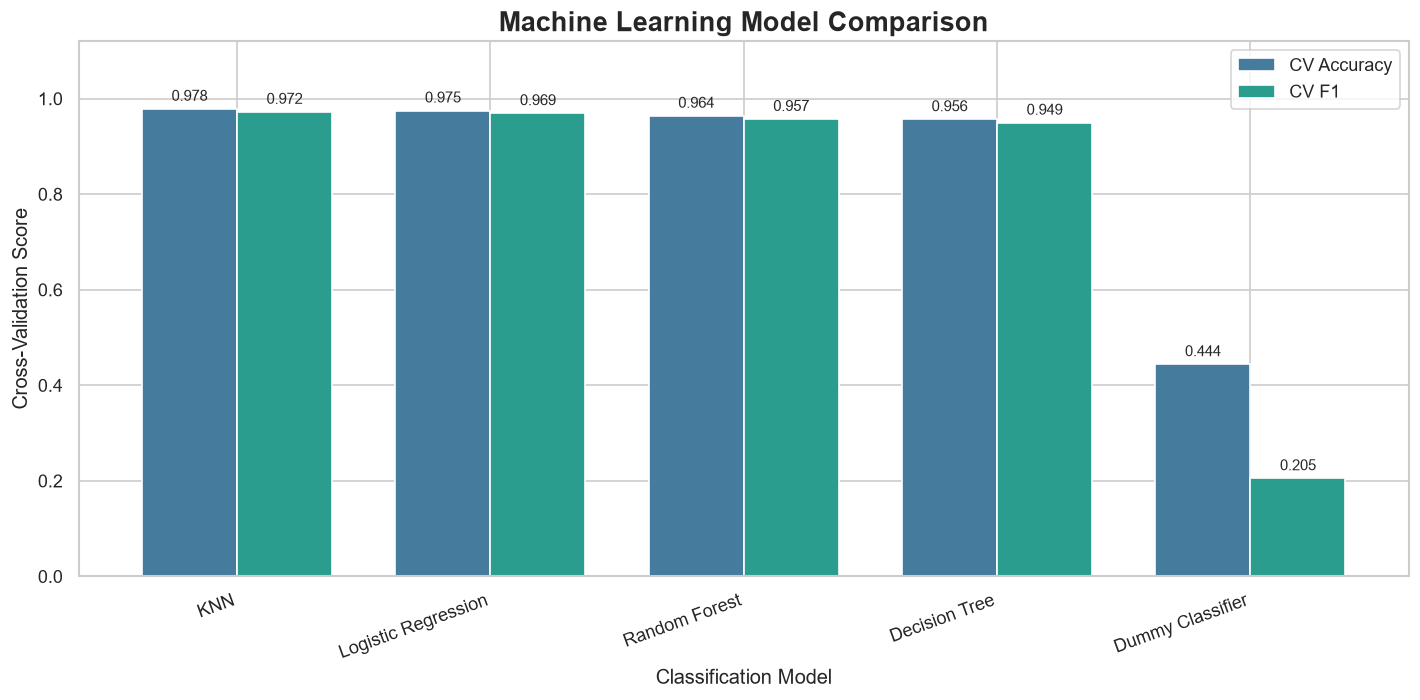

In [54]:
ax = results_df.set_index("Model")[
    ["CV Accuracy", "CV F1"]
].plot(
    kind="bar",
    figsize=(12, 6),
    color=["#457B9D", "#2A9D8F"],
    width=0.75
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

plt.title(
    "Machine Learning Model Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Classification Model")
plt.ylabel("Cross-Validation Score")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.12)
plt.legend(loc="upper right")

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [55]:
best_model_name = results_df.loc[0, "Model"]

best_model = models[best_model_name]

print("Best Model:", best_model_name)

print(
    "Best CV F1-Score:",
    round(results_df.loc[0, "CV F1"], 4)
)

Best Model: KNN
Best CV F1-Score: 0.9719


#### Key Insights

- The Dummy Classifier provides a baseline for
  evaluating meaningful predictive performance.

- Cross-validation allows models to be compared
  using multiple training and validation subsets.

- Macro F1-score accounts for performance across
  all three penguin species.

- The highest-performing model is selected based
  on training-set cross-validation results.

- The held-out test dataset is reserved for
  final model evaluation.

### 15.8 Final Model Training and Evaluation

The selected classification pipeline is trained
using the complete training dataset.

Its performance is evaluated on the previously
held-out test dataset using accuracy, precision,
recall and macro F1-score.

In [56]:
# Train selected model
best_model.fit(X_train, y_train)

# Generate predictions
y_pred = best_model.predict(X_test)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_pred)

test_precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

print("Selected Model:", best_model_name)

print(f"Test Accuracy:  {test_accuracy:.2%}")
print(f"Test Precision: {test_precision:.2%}")
print(f"Test Recall:    {test_recall:.2%}")
print(f"Test F1-Score:  {test_f1:.2%}")

Selected Model: KNN
Test Accuracy:  100.00%
Test Precision: 100.00%
Test Recall:    100.00%
Test F1-Score:  100.00%


In [57]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score"
    ],
    "Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

final_metrics.style.format({
    "Score": "{:.2%}"
})

,Metric,Score
0,Accuracy,100.00%
1,Macro Precision,100.00%
2,Macro Recall,100.00%
3,Macro F1-Score,100.00%


### 15.9 Classification Report

The classification report provides class-specific
precision, recall, F1-score and support.

This allows the performance of the selected model
to be examined individually for Adelie, Chinstrap
and Gentoo penguins.

In [58]:
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



In [59]:
report_df = pd.DataFrame(
    classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )
).T

report_df.style.background_gradient(
    subset=["precision", "recall", "f1-score"],
    cmap="YlGn"
).format("{:.3f}")

,precision,recall,f1-score,support
Adelie,1.000,1.000,1.000,30.000
Chinstrap,1.000,1.000,1.000,14.000
Gentoo,1.000,1.000,1.000,25.000
accuracy,1.000,1.000,1.000,1.000
macro avg,1.000,1.000,1.000,69.000
weighted avg,1.000,1.000,1.000,69.000


### 15.10 Confusion Matrix Analysis

A confusion matrix compares actual species labels
with predicted species labels.

Diagonal values represent correct predictions,
while off-diagonal values represent classification
errors.

This analysis helps identify which penguin species
are more frequently misclassified.

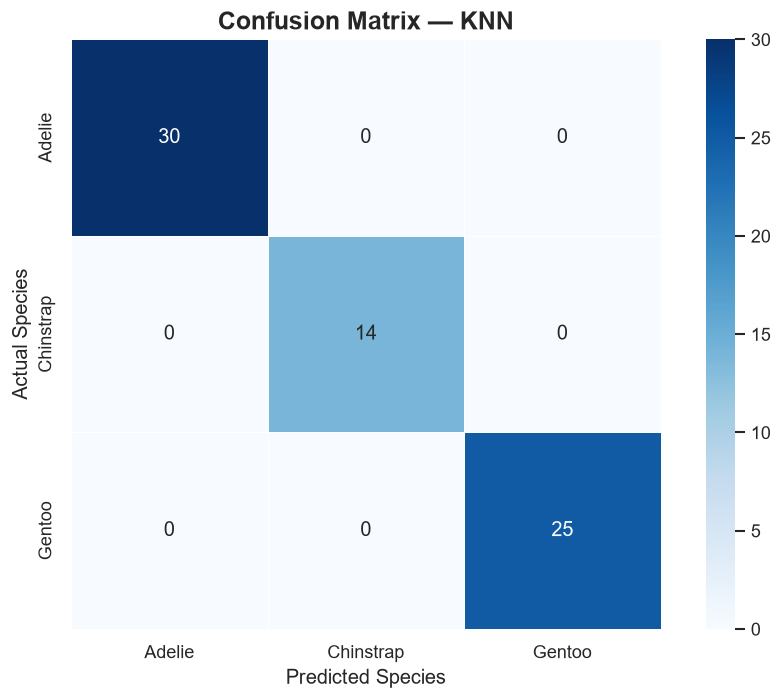

In [60]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=species_order
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=species_order,
    yticklabels=species_order,
    linewidths=0.5,
    square=True
)

plt.title(
    f"Confusion Matrix — {best_model_name}",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [61]:
correct = np.trace(cm)

incorrect = cm.sum() - correct

print("Total predictions:", cm.sum())
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)

Total predictions: 69
Correct predictions: 69
Incorrect predictions: 0


In [62]:
prediction_analysis = X_test.copy()

prediction_analysis["Actual Species"] = y_test

prediction_analysis["Predicted Species"] = y_pred

misclassified = prediction_analysis[
    prediction_analysis["Actual Species"] !=
    prediction_analysis["Predicted Species"]
]

misclassified

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,Actual Species,Predicted Species


### 15.11 Feature Importance Analysis

Permutation importance is used to estimate the
contribution of individual features to the selected
model's predictive performance.

Each feature is randomly shuffled, and the resulting
change in macro F1-score is measured.

A larger decrease in performance indicates greater
predictive importance for the fitted model.

In [63]:
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=30,
    random_state=42
)

importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.round(4)

,Feature,Importance,Std
0,bill_length_mm,0.3461,0.0458
1,bill_depth_mm,0.1451,0.0379
3,body_mass_g,0.0897,0.0348
2,flipper_length_mm,0.0570,0.0209


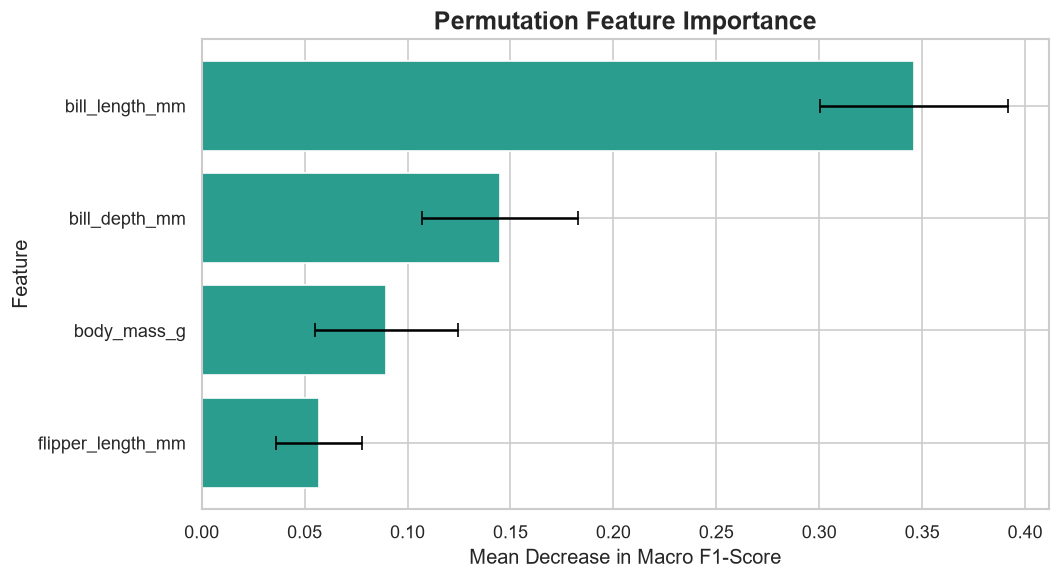

In [64]:
plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Std"],
    color="#2A9D8F",
    capsize=4
)

plt.gca().invert_yaxis()

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title(
    "Permutation Feature Importance",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Mean Decrease in Macro F1-Score")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    VISUAL_DIR / "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Key Insights

- Feature importance provides information about
  the selected model's reliance on physical measurements.

- Features producing larger decreases in model
  performance demonstrate greater permutation importance.

- Correlated features may share predictive information.

- Feature importance does not establish causation.

- The results should be interpreted cautiously due
  to the relatively small test dataset.

### 15.12 Predicting New Observations

The trained classification pipeline is used to
predict penguin species for previously unseen
physical measurements.

The pipeline automatically applies the preprocessing
steps learned during model training.

In [65]:
new_penguins = pd.DataFrame({

    "bill_length_mm": [39.5, 49.5, 47.5],

    "bill_depth_mm": [18.5, 19.0, 14.5],

    "flipper_length_mm": [190, 195, 220],

    "body_mass_g": [3700, 3800, 5200]

})

new_predictions = best_model.predict(
    new_penguins
)

prediction_results = new_penguins.copy()

prediction_results["Predicted Species"] = (
    new_predictions
)

prediction_results

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,Predicted Species
0,39.5,18.5,190,3700,Adelie
1,49.5,19.0,195,3800,Chinstrap
2,47.5,14.5,220,5200,Gentoo


In [66]:
probabilities = best_model.predict_proba(
    new_penguins
)

probability_df = pd.DataFrame(
    probabilities,
    columns=best_model.classes_
)

probability_df.style.format("{:.2%}")

,Adelie,Chinstrap,Gentoo
0,100.00%,0.00%,0.00%
1,0.00%,100.00%,0.00%
2,0.00%,0.00%,100.00%


In [67]:
def predict_species(
    bill_length,
    bill_depth,
    flipper_length,
    body_mass
):

    penguin = pd.DataFrame([{
        "bill_length_mm": bill_length,
        "bill_depth_mm": bill_depth,
        "flipper_length_mm": flipper_length,
        "body_mass_g": body_mass
    }])

    prediction = best_model.predict(penguin)[0]

    return prediction

In [68]:
result = predict_species(
    bill_length=48.0,
    bill_depth=14.5,
    flipper_length=215,
    body_mass=5000
)

print("Predicted Penguin Species:", result)

Predicted Penguin Species: Gentoo


### 15.13 Model Persistence

The trained machine learning pipeline is saved using
Joblib.

Saving the complete pipeline preserves both the
preprocessing steps and the trained classification model.

The saved model can be reused without retraining.

In [69]:
MODEL_DIR = ROOT / "models"

MODEL_DIR.mkdir(exist_ok=True)

model_path = MODEL_DIR / "penguin_classifier.joblib"

joblib.dump(
    best_model,
    model_path
)

print("Model saved successfully!")
print("Model location:", model_path)

Model saved successfully!
Model location: c:\Users\YAMINI\OneDrive\Desktop\Palmer-Penguine-Data-Science\models\penguin_classifier.joblib


In [70]:
loaded_model = joblib.load(model_path)

loaded_predictions = loaded_model.predict(
    new_penguins
)

print("Loaded model predictions:")
print(loaded_predictions)

assert np.array_equal(
    new_predictions,
    loaded_predictions
)

print("Model verification successful!")

Loaded model predictions:
['Adelie' 'Chinstrap' 'Gentoo']
Model verification successful!


In [71]:
RESULTS_DIR = ROOT / "results"

RESULTS_DIR.mkdir(exist_ok=True)

results_df.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

final_metrics.to_csv(
    RESULTS_DIR / "final_model_metrics.csv",
    index=False
)

importance_df.to_csv(
    RESULTS_DIR / "feature_importance.csv",
    index=False
)

report_df.to_csv(
    RESULTS_DIR / "classification_report.csv"
)

print("Model evaluation results saved successfully!")

Model evaluation results saved successfully!


## 16. Machine Learning Conclusion

Multiple supervised classification algorithms were
developed and evaluated using the Palmer Penguins dataset.

### Methodology

- Four physical measurements were selected as predictors.
- Stratified train-test splitting was performed.
- Median imputation and feature scaling were implemented
  through preprocessing pipelines.
- Five classification models were compared using
  stratified five-fold cross-validation.
- Macro F1-score was used for model selection.
- The selected model was evaluated on held-out test data.
- Permutation importance was used for model interpretation.
- The trained pipeline was saved for future predictions.

### Limitations

- The dataset contains a relatively small sample size.
- The model is limited to three known penguin species.
- External validation on independently collected data
  has not been performed.
- Feature importance may be affected by correlated
  predictors.
- Predictions outside the observed measurement ranges
  may be unreliable.
- Exploratory analysis used the full dataset, which may
  influence feature selection and evaluation estimates.

### Future Improvements

- Hyperparameter tuning using GridSearchCV.
- Validation using independently collected observations.
- Comparison with additional classification algorithms.
- Development of an interactive Streamlit application.

In [72]:
from IPython.display import Markdown, display

display(Markdown(f"""
### Final Model Performance

| Metric | Result |
|---|---|
| Selected Model | {best_model_name} |
| Training Observations | {len(X_train)} |
| Testing Observations | {len(X_test)} |
| Cross-Validation Macro F1 | {results_df.loc[0, "CV F1"]:.2%} |
| Test Accuracy | {test_accuracy:.2%} |
| Test Macro Precision | {test_precision:.2%} |
| Test Macro Recall | {test_recall:.2%} |
| Test Macro F1 | {test_f1:.2%} |
| Correct Predictions | {correct} |
| Incorrect Predictions | {incorrect} |
| Most Important Feature | {importance_df.iloc[0]["Feature"]} |

The selected model demonstrates the feasibility of
predicting penguin species using physical measurements
within the available dataset.
"""))


### Final Model Performance

| Metric | Result |
|---|---|
| Selected Model | KNN |
| Training Observations | 275 |
| Testing Observations | 69 |
| Cross-Validation Macro F1 | 97.19% |
| Test Accuracy | 100.00% |
| Test Macro Precision | 100.00% |
| Test Macro Recall | 100.00% |
| Test Macro F1 | 100.00% |
| Correct Predictions | 69 |
| Incorrect Predictions | 0 |
| Most Important Feature | bill_length_mm |

The selected model demonstrates the feasibility of
predicting penguin species using physical measurements
within the available dataset.


In [73]:
from importlib.metadata import version

packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "joblib",
    "notebook",
    "ipykernel",
    "ipython",
    "jinja2"
]

requirements = []

for package in packages:
    try:
        requirements.append(
            f"{package}=={version(package)}"
        )
    except Exception:
        requirements.append(package)

(ROOT / "requirements.txt").write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print("requirements.txt created successfully!")

requirements.txt created successfully!
